# RTDose module

This module contains functions for working with RT Dose, CT image and RT Structures in DICOM files.


## Dose volume histogram

In [ ]:
import Dosepy.rtdose as rt

# Load the DICOM files (do not forget to change this to your file path :)
dose_map = rt.load_dose("/media/luis/TOMO/Dosepy/Hombro20en1/RD_3D_arc1y2.dcm")

structure_set = rt.load_structures("/media/luis/TOMO/Dosepy/Hombro20en1/RS/RS.dcm")

print(structure_set.get_names())

# Load CT image
ct = rt.load_ct_image("/media/luis/TOMO/Dosepy/Hombro20en1/CT/")

# Get the physical coordinates of the structure "PTV_High"
ptv_coordinates = structure_set.get_coordinates("PTV_High")

# Get dose values in the structure
dose_in_ptv = rt.get_dose_in_structure(
    dose_distribution = dose_map,
    coordinates = ptv_coordinates,
)

# Show the Dose Volume Histogram (DVH)
rt.plot_dvh(dose_in_ptv)

 To get **Dx**: minimum dose received by the hottest sub volume x
(e.g., D20%[Gy])

In [ ]:
import numpy as np

# Volume as percentage
volume = 20  

# Minimum dose to the hottest 20% of the volume
D20 = np.percentile(dose_in_ptv, 100 - volume)

# Compare with TPS (Eclipse v16)
reference = 3.55  # Dose reported by the TPS
difference = 100 * (D20 - reference) / reference  # Percentage

print("PTV_High")
print(f"D20% (Dosepy) = {D20:.2f} Gy")
print(f"D20% (Reference TPS) = {reference:.2f} Gy")
print(f"Difference = {difference:.2f} %")

The 2.54% difference may be attributed to variation in the interpolation method used by the TPS and Dosepy to associate a dose to a point in the structure. To observe this effect, let's analyze a structure with a larger volume, such as the "BODY" structure where the physical resolution and interpolation becomes less influential.

In [ ]:
# Print structures

structure_set.get_names()

In [ ]:
# Create the DVH for BODY
body_coordinates = structure_set.get_coordinates("BODY")

dose_in_body = rt.get_dose_in_structure(
    dose_distribution=dose_map,
    coordinates=body_coordinates,
)

# Show the Dose Volume Histogram (DVH) for BODY
rt.plot_dvh(dose_in_body)

In [ ]:
# Dose to the hotest 20% of the volume
D20p = np.percentile(dose_in_body, 100 - volume)

# Compare with TPS (Eclipse v16)
reference = 1.13
difference = 100 * (D20p - reference) / reference

print("BODY")
print(f"D20% (Dosepy) = {D20p:.2f} Gy")
print(f"D20% (Reference TPS) = {reference:.2f} Gy")
print(f"Difference = {difference:.2f} %")

## Numpy mask

It is useful to generate boolean masks for visualization or to extract values inside a region of interest. The next example uses the dose distribution as a reference for the physical resolution and size of the mask, but a CT image can be used as well.

In [ ]:
from Dosepy.rtdose import get_2D_mask_by_coordinates_and_image_shape
import plotly.express as plt

ptv_mask = get_2D_mask_by_coordinates_and_image_shape(
    coordinates = ptv_coordinates[0],  # The first slice (an the only one in this example)
    image = dose_map
)

plt.imshow(ptv_mask)

## Dose object

The RTDose module leverages the SimpleITK library, utilizing the **Image** class to represent dose distributions. This allows users to access the full suite of methods and functionalities provided by SimpleITK for image processing and analysis. For example, you can easily manipulate, resample, or visualize dose distributions using familiar SimpleITK operations.

In [ ]:
# Basic image attributes

print(f"DICOM origin: {dose_map.GetOrigin()}")
print(f"Size: {dose_map.GetSize()}")
print(f"Spacing: {dose_map.GetSpacing()}")
print(f"Direction: {dose_map.GetDirection()}\n")

For more information on the SimpleITK Image class, refer to the [SimpleITK documentation](https://insightsoftwareconsortium.github.io/SimpleITK-Notebooks/Python_html/03_Image_Details.html).

Conversion to numpy array and plotting:

In [ ]:

import SimpleITK as sitk

plt.imshow(sitk.GetArrayFromImage(dose_map[:, :, 30]))

### DICOM Reference Coordinate System

The DICOM standard defines a Reference Coordinate System (RCS) which is oriented with respect to the patient. The RCS allows us to measure the position and orientation of an image relative to the patient.

![DICOMCoordinateReferenceSystem](../assets/DICOM_Coordinate_Reference_System.png)

* **The positive X direction** points to the patient's left.
* **The positive Y direction** points towards the patient's back (anterior to posterior).
* **The positive Z direction** points towards the patient's head (inferior to superior).

## EQD2 conversion

In [ ]:
import Dosepy.rtdose as rt

# Load the DICOM files
dose_map = rt.load_dose("/media/luis/TOMO/Dosepy/Hombro20en1/RD_3D_arc1y2.dcm")
structure_set = rt.load_structures("/media/luis/TOMO/Dosepy/Hombro20en1/RS/RS.dcm")

rt.eqd2(
    dose_distribution = dose_map,
    fractions = 1,
    structures = structure_set,
    alpha_beta = {
        "PTV_High": 10,
    }
)

In [ ]:
# Read CT image
# Read dose distribution 
# Read structure set

# Resample dose distribution on CT points

# Create mask on CT image shape and resolution
# Get doses in the mask
# 
import SimpleITK as sitk
from Dosepy import rtdose as rt

ct = rt.load_ct_image("/media/luis/TOMO/Dosepy/Hombro20en1/CT/")
dose_map = rt.load_dose("/media/luis/TOMO/Dosepy/Hombro20en1/RD_3D_arc1y2.dcm")
structure_set = rt.load_structures("/media/luis/TOMO/Dosepy/Hombro20en1/RS/RS.dcm")

In [ ]:
ct.GetOrigin()

In [ ]:
dose_map.GetOrigin()

In [ ]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(1,2)
ax[0].imshow(sitk.GetArrayFromImage(dose_map[:, :, 30]))
z_point = dose_map.TransformContinuousIndexToPhysicalPoint((0,0,30))[2]

z_index = interpolated_dose.TransformPhysicalPointToContinuousIndex((0,0,z_point))[2]
print(z_index)
ax[1].imshow(sitk.GetArrayFromImage(interpolated_dose[:, :, int(z_index)]))
print(z_point)

In [ ]:
plt.imshow(sitk.GetArrayFromImage(ct[:, :, 30]))

In [ ]:
plt.imshow(sitk.GetArrayFromImage(interpolated_dose[:, :, 60]))

z_index = interpolated_dose.TransformPhysicalPointToContinuousIndex((0,0,z_point))[2]
print(f"{z_index=}")

# Get physical position in Z direction, based on index
z_origin = interpolated_dose.GetOrigin()[2]
z_spacing = interpolated_dose.GetSpacing()[2]

z_position = z_origin + z_spacing*30
print("Manual calculation:")
print(z_position)

print(interpolated_dose.TransformIndexToPhysicalPoint((0,0,30)))


In [ ]:
ct[:,:,0].GetSpacing()
ct[:,:,0].GetSize()

interpolated_dose = sitk.Resample(
        dose_map,
        ct,
        sitk.Transform(3, sitk.sitkIdentity),
        sitk.sitkLinear,
    )

In [ ]:
print(dose_map.GetSize())
print(interpolated_dose.GetSize())


In [ ]:
# Get the vertices of the structure "PTV_High"
ptv_coordinates = structure_set.get_coordinates("PTV_High")

dose_in_structure = []
i = 0
for slice_coordinates in ptv_coordinates:
    # Check that each slice_coordinates has a constant z coordinate
    if not len(set(slice_coordinates[:, 2])) == 1:
        raise ValueError("Each slice_coordinates must have a constant z coordinate.")
    
    z_coordinate = slice_coordinates[0, 2]

    dose_2D = rt.get_axial_dose_plane(interpolated_dose, z_coordinate)

    dose_in_structure_in_slice = rt.get_dose_in_structure_by_plane(dose_2D, slice_coordinates)

    dose_in_structure.extend(dose_in_structure_in_slice)
    print(i)

# Structure resolution

In [ ]:
ptv_coordinates[0]

In [ ]:
len(ptv_coordinates)

# Show CT and PTV structure

In [ ]:
z_physical_for_structure = 1
z_ct_index_ptv = ct.TransformPhysicalPointToContinuousIndex((0, 0, z_physical_for_structure))[2]
print(z_ct_index_ptv)

# Create the mask
ptv_mask = rt.get_2D_mask_by_coordinates_and_image_shape(ptv_coordinates[0], ct[:,:,0])
ptv_mask_ma = np.ma.masked_where(ptv_mask == 0, ptv_mask)
print(ptv_mask_ma.size)

fig, ax = plt.subplots(1,1)
ax.imshow(sitk.GetArrayFromImage(ct[:, :, int(z_ct_index_ptv)]), cmap="gray")
ax.imshow(ptv_mask_ma, alpha=0.5)


In [ ]:
import numpy as np

# Volume as percentage
volume = 20  

# Minimum dose to the hottest 20% of the volume
D20 = np.percentile(dose_in_structure, 100 - volume, method="weibull")

# Compare with TPS (Eclipse v16)
reference = 3.55  # Dose reported by the TPS
difference = 100 * (D20 - reference) / reference  # Percentage

print("PTV_High")
print(f"D20% (Dosepy) = {D20:.2f} Gy")
print(f"D20% (Reference TPS) = {reference:.2f} Gy")
print(f"Difference = {difference:.2f} %")

In [ ]:
for slice_coodinate in body_coordinates:
    #print(slice_coodinate[2])
    pass

ct.GetOrigin()
ct.GetSpacing()

In [ ]:
from Dosepy import rtdose

print(structure_set.get_names())
couch_contour = structure_set.get_roi_contour(4)
#print(couch_contour)
print(couch_contour.ContourSequence)

types = set()
for contour_sequence in couch_contour.ContourSequence:
    #print(contour)
    print(contour_sequence.ContourGeometricType)
    types.add(contour_sequence.ContourGeometricType)

print(len(types))

ct.GetSize()

rt_set = rtdose.RTSet()
rt_set.load_ct_image()

In [ ]:
from Dosepy import rtdose as rt

rtset = rt.RTSet()
rtset.load_ct_image("/media/luis/TOMO/Dosepy/Hombro20en1/CT/")
rtset.load_dose("/media/luis/TOMO/Dosepy/Hombro20en1/RD_3D_arc1y2.dcm")
rtset.load_structures("/media/luis/TOMO/Dosepy/Hombro20en1/RS/RS.dcm")

ptv_mask = rtset.create_structure_mask(2)
print(rtset.ss.get_names())

In [ ]:
import matplotlib.pyplot as plt
import SimpleITK as sitk
import numpy as np

fig, ax = plt.subplots(1,1)
ax.imshow(sitk.GetArrayFromImage(rtset.ct[:, :, 60]), cmap="gray")
mx = np.ma.masked_array(ptv_mask, mask=~ptv_mask)
ax.imshow(mx[60,:,:], alpha=0.5)

#ax.imshow(sitk.LabelOverlay(rtset.ct[:,:,25], ptv_mask[:,:,25]))
rtset.ct.TransformPhysicalPointToIndex((0,0,1))
#plt.hist(ptv_mask.flatten())

{'BODY': 1, 'CouchSurface': 2, 'CouchInterior': 3, 'PTV_High': 4, 'NS_Ring': 5, 'PRV': 6, 'NS_Control': 7}
CLOSED_PLANAR
Updating mask_3d.....
CLOSED_PLANAR
Updating mask_3d.....
CLOSED_PLANAR
Updating mask_3d.....
CLOSED_PLANAR
CLOSED_PLANAR
Updating mask_3d.....
CLOSED_PLANAR
CLOSED_PLANAR
Updating mask_3d.....
CLOSED_PLANAR
CLOSED_PLANAR
Updating mask_3d.....
CLOSED_PLANAR
CLOSED_PLANAR
Updating mask_3d.....
CLOSED_PLANAR
CLOSED_PLANAR
Updating mask_3d.....
CLOSED_PLANAR
CLOSED_PLANAR
Updating mask_3d.....
CLOSED_PLANAR
CLOSED_PLANAR
Updating mask_3d.....
CLOSED_PLANAR
CLOSED_PLANAR
Updating mask_3d.....
CLOSED_PLANAR
CLOSED_PLANAR
Updating mask_3d.....
CLOSED_PLANAR
CLOSED_PLANAR
Updating mask_3d.....
CLOSED_PLANAR
CLOSED_PLANAR
Updating mask_3d.....
CLOSED_PLANAR
Updating mask_3d.....
CLOSED_PLANAR
Updating mask_3d.....
CLOSED_PLANAR
Updating mask_3d.....
CLOSED_PLANAR
Updating mask_3d.....
CLOSED_PLANAR
Updating mask_3d.....
CLOSED_PLANAR
Updating mask_3d.....
CLOSED_PLANAR
Updat

array([[-1000, -1000, -1000, ..., -1000, -1000, -1000],
       [-1000, -1000, -1000, ..., -1000, -1000, -1000],
       [-1000, -1000, -1000, ..., -1000, -1000, -1000],
       ...,
       [-1000, -1000, -1000, ..., -1000, -1000, -1000],
       [-1000, -1000, -1000, ..., -1000, -1000, -1000],
       [-1000, -1000, -1000, ..., -1000, -1000, -1000]],
      shape=(512, 512), dtype=int32)

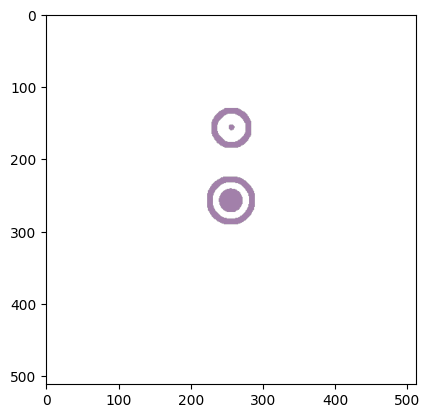

In [5]:
path_to_ring_plan = "/media/luis/TOMO/Dosepy/EQD2/zz_Cubo_Anillo/"

from Dosepy import rtdose as rt

rtset = rt.RTSet()
rtset.load_ct_image("/media/luis/TOMO/Dosepy/EQD2/zz_Cubo_Anillo/CT/")
rtset.load_dose("/media/luis/TOMO/Dosepy/EQD2/zz_Cubo_Anillo/RD.dcm")
#rtset.load_structures("/media/luis/TOMO/Dosepy/EQD2/zz_Cubo_Anillo/RS.dcm")
rtset.load_structures("/media/luis/TOMO/Dosepy/EQD2/zz_Cubo_Anillo/RS_Esfera&Anillo.dcm")

print(rtset.ss.get_names())

ring = rtset.create_structure_mask(5)
ptv = rtset.create_structure_mask(4)
esfera_anillo = rtset.create_structure_mask(7)

import matplotlib.pyplot as plt
import SimpleITK as sitk
import numpy as np

fig, ax = plt.subplots(1,1)
#ax.imshow(sitk.GetArrayFromImage(rtset.ct[:, :, 40]), cmap="gray")
mx = np.ma.masked_array(esfera_anillo, mask=~esfera_anillo)
ax.imshow(mx[40,:,:], alpha=0.5)
mx = np.ma.masked_array(ptv, mask=~ptv)
ax.imshow(mx[40,:,:], alpha=0.5)
mx = np.ma.masked_array(ring, mask=~ring)
ax.imshow(mx[40,:,:], alpha=0.5)
#ax.imshow(sitk.LabelOverlay(rtset.ct[:,:,25], ptv_mask[:,:,25]))
print(rtset.ct.TransformPhysicalPointToIndex((0,0,0)))

sitk.GetArrayFromImage(rtset.ct[:, :, 40])


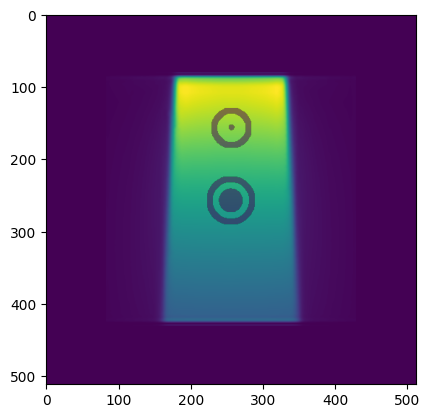

In [10]:
dose_in_ct = rtset.resample_dose_in_ct_positions()
dose_2D = sitk.GetArrayFromImage(dose_in_ct[:,:,40])
fig, ax = plt.subplots(1,1)
ax.imshow(dose_2D)
mx = np.ma.masked_array(esfera_anillo, mask=~esfera_anillo)
ax.imshow(mx[40,:,:], alpha=0.5)
mx = np.ma.masked_array(ptv, mask=~ptv)
ax.imshow(mx[40,:,:], alpha=0.5)
mx = np.ma.masked_array(ring, mask=~ring)
ax.imshow(mx[40,:,:], alpha=0.5)

In [21]:
dose_in_ct_array = sitk.GetArrayFromImage(dose_in_ct)
print(f"Mean dose in PTV_High: {np.mean(dose_in_ct_array[ptv])}")
print(f"Min dose in PTV: {np.min(dose_in_ct_array[ptv])}")
print(f"Min dose in PTV: {np.max(dose_in_ct_array[ptv])}")

print(f"Mean dose in Ring: {np.mean(dose_in_ct_array[ring])}")
print(f"Min dose in Ring: {np.min(dose_in_ct_array[ring])}")
print(f"Min dose in Ring: {np.max(dose_in_ct_array[ring])}")

Mean dose in PTV_High: 2.000094775216757
Min dose in PTV: 1.8793883626372012
Min dose in PTV: 2.1257017130107765
Mean dose in Ring: 2.0003635988893107
Min dose in Ring: 1.7683742024775313
Min dose in Ring: 2.2543692137039333
